# Poor man's ETF: a walkthrough

An S&P 500 index fund holds ~500 stocks. Can we get most of the way there with **20**?

This notebook walks through the method step by step. Everything here calls the
`poor_mans_etf` package, so the same results are available from the command line
(`poor-mans-etf run --k 20`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from poor_mans_etf.backtest import Backtest
from poor_mans_etf.data import load_universe
from poor_mans_etf.plots import LIGHT, apply_theme
from poor_mans_etf.tracking import annualise, optimal_weights, restrict

apply_theme(LIGHT)
pd.options.display.float_format = "{:.4f}".format

## 1. The data

Three years of daily prices for the current S&P 500 constituents and for SPY, from Yahoo
Finance (cached in `data/`). One share class per company, and only stocks with a full
price history. We fit on the first two years and keep the last year as an untouched test
set.

In [2]:
universe = load_universe()
bt = Backtest(universe)

print(f"{len(universe)} stocks")
print(f"train: {bt.train.prices.index[0]:%Y-%m-%d} to {bt.train.prices.index[-1]:%Y-%m-%d}")
print(f"test:  {bt.test.prices.index[0]:%Y-%m-%d} to {bt.test.prices.index[-1]:%Y-%m-%d}")
universe.sectors.value_counts()

487 stocks
train: 2023-06-29 to 2025-06-30
test:  2025-06-30 to 2026-06-26


sector
Industrials               77
Financials                76
Information Technology    72
Health Care               58
Consumer Discretionary    47
Consumer Staples          33
Utilities                 31
Real Estate               29
Materials                 26
Energy                    21
Communication Services    17
Name: count, dtype: int64

## 2. Tracking error

The quantity we care about is **tracking error**: how much the portfolio's daily return
wanders from the benchmark's. With stock returns $r$, benchmark return $r_b$ and weights $w$,

$$\mathrm{TE}^2 = \operatorname{Var}(w^\top r - r_b) = a^\top \Sigma_{\text{aug}}\, a, \qquad a = \begin{bmatrix} w \\ -1 \end{bmatrix}$$

where $\Sigma_{\text{aug}}$ is the covariance matrix of the stocks *and* the benchmark. We
quote it annualised, $\sqrt{252}\,\sigma_{\text{daily}}$.

The obvious way to build a small index is to hold the $K$ biggest companies, weighted by
market cap:

In [3]:
naive = bt.naive(20)
print(f"Top-20 by market cap: {naive.sum():.0%} invested in {len(naive)} stocks")
print(f"training-window tracking error: {bt.fit_tracking_error(naive):.2%}")
naive.head(10)

Top-20 by market cap: 100% invested in 20 stocks
training-window tracking error: 9.69%


NVDA    0.1426
MSFT    0.1380
AAPL    0.1114
AMZN    0.0886
GOOGL   0.0810
META    0.0705
AVGO    0.0492
TSLA    0.0469
BRK-B   0.0386
WMT     0.0291
dtype: float64

That's poor: almost 10% a year. The 20 biggest companies are mostly tech, so the
portfolio is really a tech fund.

## 3. The inner problem: best weights for a given basket

For a *fixed* set of stocks, the best long-only weights solve a small convex quadratic
program:

$$\min_w \; a^\top \Sigma_{\text{aug}}\, a \quad \text{s.t.} \quad w \ge 0,\; \textstyle\sum w = 1$$

`optimal_weights` turns this into a non-negative least-squares problem via a Cholesky
factorisation, which is about 40x faster than a general solver like SLSQP. Just
reweighting the *same* 20 stocks already helps a lot:

In [4]:
tickers = universe.tickers
basket = [tickers.index(t) for t in naive.index]
variance, w = optimal_weights(restrict(bt.sigma, basket))
print(f"same 20 stocks, optimal weights: {annualise(variance):.2%}")

same 20 stocks, optimal weights: 3.80%


## 4. The outer problem: which 20 stocks?

There are $\binom{487}{20} \approx 10^{35}$ baskets, far too many to try. **Simulated
annealing** walks between baskets instead:

1. Propose a neighbour: swap one held stock for one not held.
2. Score it by the tracking error of its optimal weights (the inner problem above).
3. Accept it if it's better, and *sometimes* if it's worse, with probability
   $e^{-\Delta/T}$.
4. Cool down: $T \leftarrow \alpha T$.

Early on, the high temperature lets the search escape poor regions. As $T$ falls, it
settles. The starting temperature is calibrated so ~80% of uphill moves are accepted at
first.

best basket: 2.71% tracking error in the training window


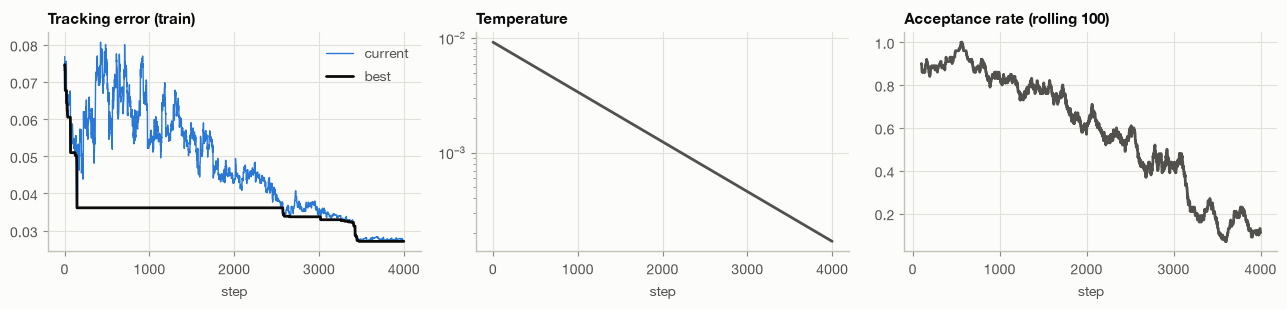

In [5]:
annealed, result = bt.anneal(20, n_steps=4000, seed=0)
h = result.history

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].plot(h.index, h.tracking_error, lw=1, color="#2a78d6", label="current")
axes[0].plot(h.index, h.best_tracking_error, color="#0b0b0b", label="best")
axes[0].set_title("Tracking error (train)")
axes[0].legend()
axes[1].semilogy(h.index, h.temperature, color="#52514e")
axes[1].set_title("Temperature")
axes[2].plot(h.index, h.accepted.rolling(100).mean(), color="#52514e")
axes[2].set_title("Acceptance rate (rolling 100)")
for ax in axes:
    ax.set_xlabel("step")
fig.tight_layout()
print(f"best basket: {result.tracking_error:.2%} tracking error in the training window")

It doesn't just pick big stocks. It spreads the basket across sectors (utilities,
energy, health care, financials) to reproduce the index's sector mix:

In [6]:
pd.DataFrame({"weight": annealed, "sector": universe.sectors[annealed.index]})

,weight,sector
MSFT,0.1132,Information Technology
AAPL,0.0887,Information Technology
DUK,0.0780,Utilities
HD,0.0650,Consumer Discretionary
XOM,0.0633,Energy
ABT,0.0632,Health Care
NVDA,0.0622,Information Technology
PH,0.0610,Industrials
AXP,0.0563,Financials
GOOGL,0.0547,Communication Services


## 5. The honest test: out of sample

Everything so far was measured on the data the optimiser saw. The real question is what
happens next. We buy each portfolio at the end of the training window and **hold it for a
year** without rebalancing:

In [7]:
rows = {
    "Simulated annealing": annealed,
    "Top-20 by market cap": naive,
}
pd.DataFrame(
    {
        "train TE": {k: bt.fit_tracking_error(w) for k, w in rows.items()},
        "test TE": {k: bt.test_tracking_error(w) for k, w in rows.items()},
    }
).style.format("{:.2%}")

,train TE,test TE
Simulated annealing,2.71%,4.66%
Top-20 by market cap,9.69%,7.42%


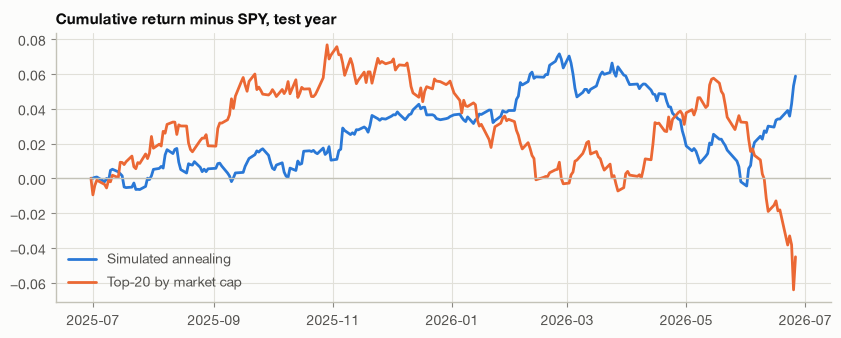

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.5))
spy = bt.benchmark_growth()
for (label, w), colour in zip(rows.items(), ["#2a78d6", "#eb6834"], strict=True):
    ax.plot(bt.growth(w) - spy, label=label, color=colour)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_title("Cumulative return minus SPY, test year")
ax.legend();

Annealing still wins out of sample, but its tracking error rises sharply from the
training window. Part of the in-sample fit was **overfitting**: the optimiser learnt noise
in two years of covariance estimates.

You can see this directly. Optimising *harder* (more steps, with the same overall cooling)
keeps improving the training fit, but past a point the test year gets worse. Too few steps
underfits, and too many overfits:

In [9]:
results = []
for steps in (1000, 4000, 16000):
    for seed in range(3):
        # Same overall cooling (T falls by a factor e^4) whatever the run length.
        w, _ = bt.anneal(20, n_steps=steps, alpha=np.exp(-4 / steps), seed=seed)
        results.append(
            {"steps": steps, "train": bt.fit_tracking_error(w), "test": bt.test_tracking_error(w)}
        )
pd.DataFrame(results).groupby("steps")[["train", "test"]].mean().style.format("{:.2%}")

,train,test
steps,,
1000,3.10%,6.14%
4000,2.65%,4.45%
16000,2.54%,5.50%


The extreme case is fitting weights to *all* 487 stocks at once. The optimiser ends
up using a couple of hundred of them, and tracks very closely in sample. Out of sample it is
still the best tracker (it holds ten times as many stocks), but its error more than doubles
too. That's the same overfitting at a larger scale:

In [10]:
everything = bt.full_universe()
print(f"{len(everything)} stocks with non-zero weight")
print(f"train TE {bt.fit_tracking_error(everything):.2%}")
print(f"test TE  {bt.test_tracking_error(everything):.2%}")

201 stocks with non-zero weight
train TE 0.96%
test TE  2.40%


## 6. Caveats

* **Survivorship bias.** The universe is *today's* S&P 500. Stocks added during the
  window (and deletions we never see) make the index harder to track early on and flatter
  the stock picks a little.
* **Share counts are current.** Market caps on past dates are today's share count times
  that day's price, which ignores buybacks and issuance.
* **No costs.** Transaction costs, taxes and dividend timing are ignored.
* **One split.** A single train/test split is one sample. A rolling backtest would give a
  distribution.

See the README for ideas on where to take this next.